# 02 – Explorative Datenanalyse

**Leitfragen**

1. Wie haben sich Preisniveau und Volatilität 2023–2025 entwickelt?
2. Welche Tages- und Saisonmuster gibt es?
3. Wie stark beeinflussen Wind und Solar den Preis (Merit-Order-Effekt)?
4. Wie häufig und unter welchen Bedingungen treten negative Preise auf?
5. Welche Variablen eignen sich für eine Preisprognose?

In [1]:
import sys
from pathlib import Path

# Projektpaket importierbar machen (alternativ: pip install -e .)
sys.path.insert(0, str(Path.cwd().parent / "src"))

In [2]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from energy_analytics.database import load_energy_data
from energy_analytics.plotting import COLORS, TEXT_MUTED, save, set_style

set_style()
df = load_energy_data()
print(f"{len(df):,} Stunden, {df['timestamp_local'].min():%d.%m.%Y} bis {df['timestamp_local'].max():%d.%m.%Y}")

26,304 Stunden, 01.01.2023 bis 31.12.2025


## 1. Preisentwicklung

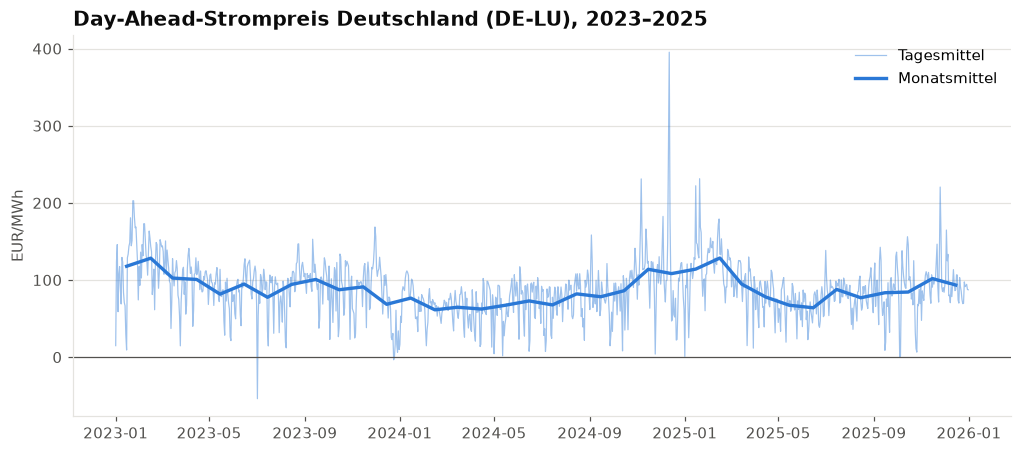

In [3]:
daily = df.set_index("timestamp_local")["price"].resample("D").mean()
monthly = df.set_index("timestamp_local")["price"].resample("MS").mean()

fig, ax = plt.subplots()
ax.plot(daily.index, daily, color=COLORS["blue"], linewidth=0.8, alpha=0.45, label="Tagesmittel")
ax.plot(monthly.index + pd.Timedelta(days=14), monthly, color=COLORS["blue"], linewidth=2.2, label="Monatsmittel")
ax.axhline(0, color=TEXT_MUTED, linewidth=0.8)
ax.set_title("Day-Ahead-Strompreis Deutschland (DE-LU), 2023–2025")
ax.set_ylabel("EUR/MWh")
ax.legend(loc="upper right")
save(fig, "price_timeseries")
plt.show()

In [4]:
yearly = df.groupby("year")["price"].agg(
    Mittelwert="mean", Median="median", Std="std", Minimum="min", Maximum="max",
    Negative_Stunden=lambda s: (s < 0).sum(),
)
yearly.round(2)

,Mittelwert,Median,Std,Minimum,Maximum,Negative_Stunden
year,,,,,,
2023,95.18,98.02,47.58,-500.00,524.27,301
2024,78.51,79.59,52.73,-135.45,936.28,457
2025,89.32,92.43,52.10,-250.32,583.40,576


**Beobachtungen**

* Nach dem Krisenjahr 2022 sinkt das Preisniveau 2024 deutlich (Ø 78,5 EUR/MWh)
  und steigt 2025 wieder an (Ø 89,3 EUR/MWh) – v. a. durch einen kalten,
  windarmen Winter 2024/25 („Dunkelflaute“ im November/Dezember 2024).
* Die Streuung bleibt mit einer Standardabweichung um 50 EUR/MWh hoch.
* Die Zahl der Stunden mit negativen Preisen steigt jedes Jahr (301 → 457 → 576).

## 2. Tages- und Saisonmuster

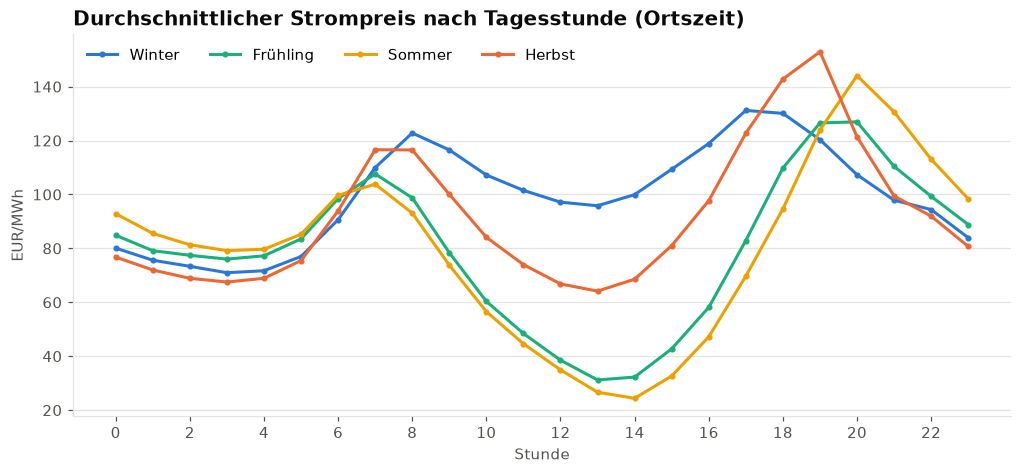

In [5]:
season_order = ["Winter", "Frühling", "Sommer", "Herbst"]
season_colors = {"Winter": COLORS["blue"], "Frühling": COLORS["aqua"],
                 "Sommer": COLORS["yellow"], "Herbst": COLORS["orange"]}
profile = df.pivot_table(index="hour", columns="season", values="price", aggfunc="mean")[season_order]

fig, ax = plt.subplots()
for season in season_order:
    ax.plot(profile.index, profile[season], color=season_colors[season], marker="o", markersize=3, label=season)
ax.set_xticks(range(0, 24, 2))
ax.set_title("Durchschnittlicher Strompreis nach Tagesstunde (Ortszeit)")
ax.set_xlabel("Stunde")
ax.set_ylabel("EUR/MWh")
ax.legend(ncol=4, loc="upper left")
save(fig, "hourly_profile_by_season")
plt.show()

Die **„Duck Curve“** ist deutlich zu erkennen: Im Frühling und Sommer fällt der
Preis zur Mittagszeit durch die Solarerzeugung auf rund 25–35 EUR/MWh und steigt
nach Sonnenuntergang auf über 120 EUR/MWh. Im Winter fehlt das Mittagstief, dafür
gibt es eine Morgen- und eine ausgeprägte Abendspitze.

Die Abendspitze liegt in Ortszeit bei 19–20 Uhr. (In der ursprünglichen
Version des Projekts wurden die Stunden in UTC berechnet – das Profil war dadurch
um ein bis zwei Stunden verschoben.)

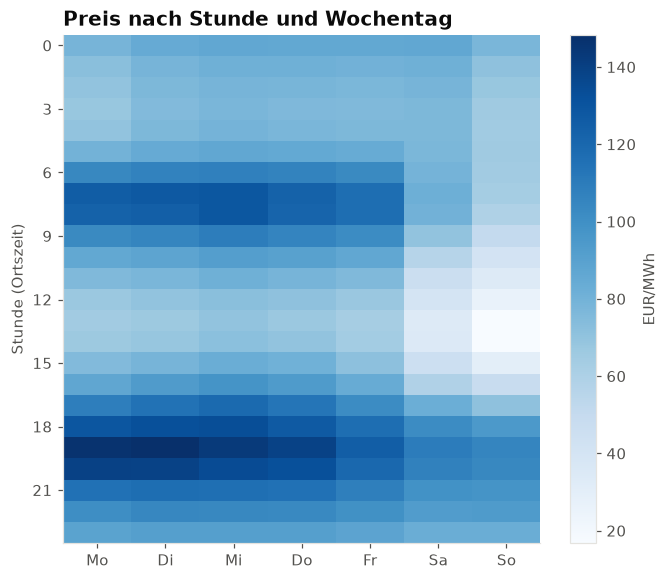

In [6]:
heat = df.pivot_table(index="hour", columns="day_of_week", values="price", aggfunc="mean")

fig, ax = plt.subplots(figsize=(7, 6))
im = ax.imshow(heat, aspect="auto", cmap="Blues")
ax.set_xticks(range(7), ["Mo", "Di", "Mi", "Do", "Fr", "Sa", "So"])
ax.set_yticks(range(0, 24, 3))
ax.grid(False)
ax.set_title("Preis nach Stunde und Wochentag")
ax.set_ylabel("Stunde (Ortszeit)")
fig.colorbar(im, ax=ax, label="EUR/MWh")
plt.show()

Am Wochenende ist der Preis tagsüber deutlich niedriger – die industrielle
Nachfrage fehlt, während die Solarerzeugung gleich bleibt.

## 3. Wind, Solar und Merit-Order-Effekt

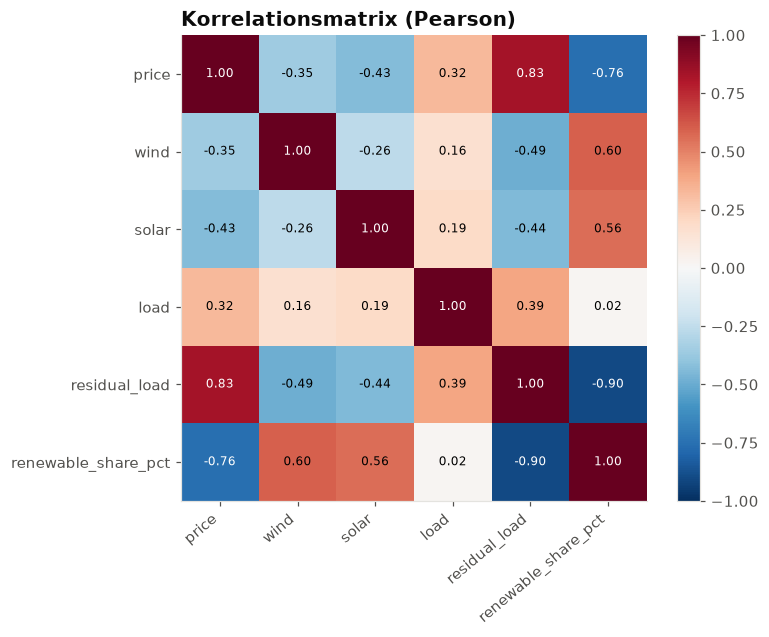

In [7]:
cols = ["price", "wind", "solar", "load", "residual_load", "renewable_share_pct"]
corr = df[cols].corr()

fig, ax = plt.subplots(figsize=(7, 5.5))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(cols)), cols, rotation=40, ha="right")
ax.set_yticks(range(len(cols)), cols)
ax.grid(False)
for i in range(len(cols)):
    for j in range(len(cols)):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=8,
                color="white" if abs(corr.iloc[i, j]) > 0.6 else "black")
ax.set_title("Korrelationsmatrix (Pearson)")
fig.colorbar(im, ax=ax)
plt.show()

Wind (−0,35) und Solar (−0,43) einzeln korrelieren nur moderat mit dem Preis.
Die **Residuallast** (Last − Wind − Solar) erklärt den Preis dagegen sehr gut
(r = 0,83): Sie bestimmt, wie viel konventionelle Erzeugung mit höheren
Grenzkosten benötigt wird – genau das beschreibt die Merit-Order.

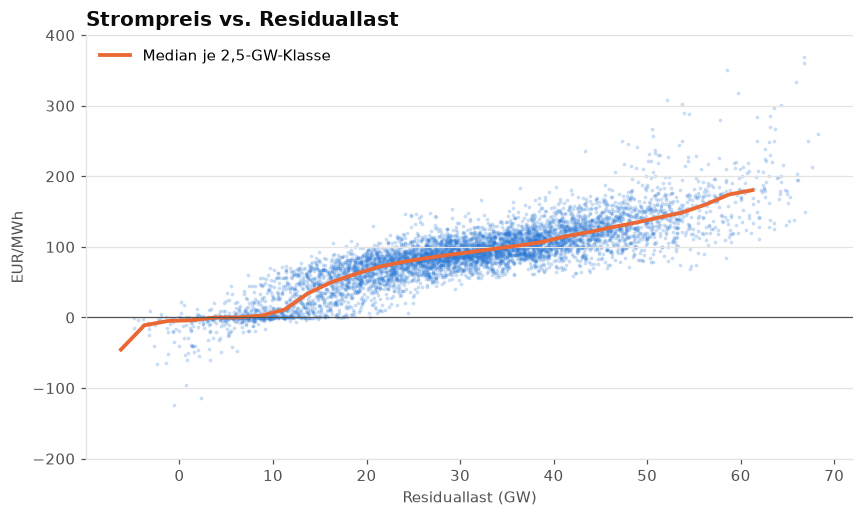

In [8]:
sample = df.sample(6000, random_state=1)

fig, ax = plt.subplots(figsize=(9, 5))
ax.scatter(sample["residual_load"] / 1000, sample["price"], s=6, alpha=0.25, color=COLORS["blue"], linewidths=0)
binned = df.groupby(pd.cut(df["residual_load"] / 1000, bins=np.arange(-10, 65, 2.5)), observed=True)["price"].median()
ax.plot([b.mid for b in binned.index], binned.values, color=COLORS["orange"], linewidth=2.5, label="Median je 2,5-GW-Klasse")
ax.axhline(0, color=TEXT_MUTED, linewidth=0.8)
ax.set_ylim(-200, 400)
ax.set_title("Strompreis vs. Residuallast")
ax.set_xlabel("Residuallast (GW)")
ax.set_ylabel("EUR/MWh")
ax.legend(loc="upper left")
save(fig, "price_vs_residual_load")
plt.show()

Der Zusammenhang ist **nicht linear**: Bei niedriger Residuallast fällt der Preis
steil bis in den negativen Bereich, bei sehr hoher Residuallast steigt er
überproportional (teure Gas-Spitzenlastkraftwerke). Das spricht für ein
nichtlineares Prognosemodell.

## 4. Negative Preise

In [9]:
neg = df[df["price"] < 0]
summary = pd.DataFrame({
    "Stunden": df.groupby("year")["is_negative_price"].sum(),
    "Anteil_%": df.groupby("year")["is_negative_price"].mean() * 100,
    "davon_Wochenende_%": neg.groupby("year")["is_weekend"].mean() * 100,
    "davon_10_bis_16_Uhr_%": neg.groupby("year")["hour"].apply(lambda h: h.between(10, 15).mean() * 100),
})
summary.round(1)

,Stunden,Anteil_%,davon_Wochenende_%,davon_10_bis_16_Uhr_%
year,,,,
2023,301,3.4,57.1,54.5
2024,457,5.2,64.1,68.7
2025,576,6.6,54.2,80.0


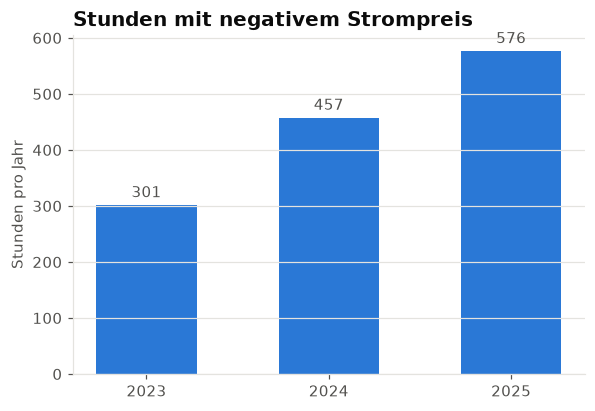

In [10]:
counts = df.groupby("year")["is_negative_price"].sum()

fig, ax = plt.subplots(figsize=(6, 4))
bars = ax.bar(counts.index.astype(str), counts.values, color=COLORS["blue"], width=0.55)
ax.bar_label(bars, padding=3, color=TEXT_MUTED)
ax.set_title("Stunden mit negativem Strompreis")
ax.set_ylabel("Stunden pro Jahr")
save(fig, "negative_hours_per_year")
plt.show()

Negative Preise entstehen überwiegend **mittags** bei hoher Solarerzeugung und
überproportional am **Wochenende** bzw. an Feiertagen. Die Zahl steigt mit dem
Ausbau der Photovoltaik – ein starkes Argument für Speicher und flexible Lasten.

## 5. Zeitliche Abhängigkeit (Autokorrelation)

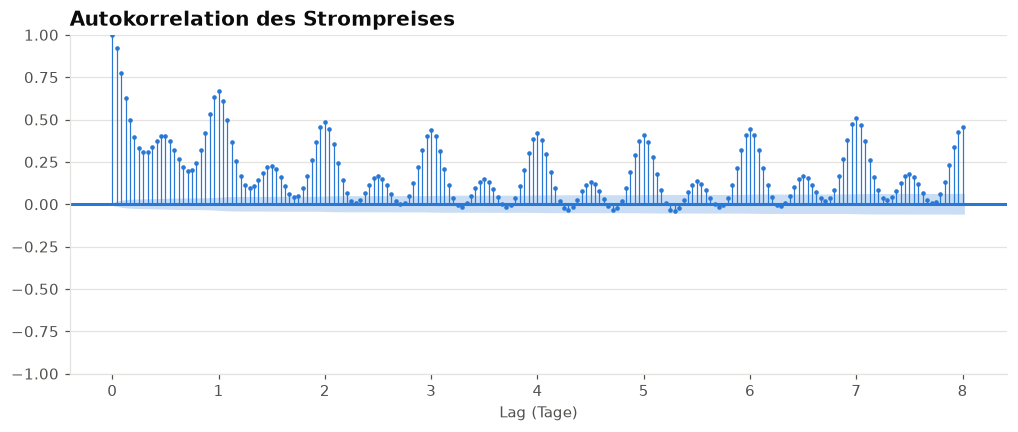

Lag   1 h: r = 0.922
Lag  24 h: r = 0.669
Lag  48 h: r = 0.489
Lag 168 h: r = 0.513


In [11]:
from statsmodels.graphics.tsaplots import plot_acf

fig, ax = plt.subplots(figsize=(11, 4))
plot_acf(df["price"], lags=24 * 8, ax=ax, markersize=2, color=COLORS["blue"],
         vlines_kwargs={"colors": COLORS["blue"], "linewidth": 0.8})
ax.set_xticks(range(0, 24 * 8 + 1, 24), range(0, 9))
ax.set_title("Autokorrelation des Strompreises")
ax.set_xlabel("Lag (Tage)")
plt.show()

for lag in (1, 24, 48, 168):
    print(f"Lag {lag:>3} h: r = {df['price'].autocorr(lag):.3f}")

Der Preis ist stark autokorreliert, mit Spitzen bei Vielfachen von 24 h und einem
Wochenzyklus (168 h). Für eine realistische Day-Ahead-Prognose sind allerdings nur
Lags **≥ 24 h** zulässig (siehe Notebook 05).

## Fazit

| Erkenntnis | Konsequenz für die Modellierung |
|---|---|
| Residuallast erklärt den Preis am besten, nichtlinear | Residuallast und EE-Anteil als Features, Baum-Modell |
| Ausgeprägte Tages-, Wochen- und Saisonmuster | Stunde, Wochentag, Monat als Features |
| Hohe Autokorrelation bei 24 h und 168 h | Lag-Features 24 h / 168 h |
| Negative Preise und Spitzen sind real | Keine Ausreißerbereinigung, Modell muss negative Werte abbilden |